# 2. Baseline classifiers
Logistic Regression, KNN, SVM (RBF), Decision Tree and Gaussian NB, compared by 5-fold CV on the training split.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
RES = ROOT/'results'; sns.set_theme(style='whitegrid')
s = pd.read_csv(RES/'summary.csv')
b = s[s.family=='Base']
b.pivot(index='model', columns='condition', values='cv_accuracy_mean').round(4)

condition,Original 30,PCA 95%,SelectKBest 15
model,,,
Decision Tree,0.9184,0.8882,0.9256
Gaussian NB,0.6504,0.9045,0.6480
KNN,0.9211,0.9209,0.9166
Logistic Regression,0.9218,0.9220,0.9188
SVM RBF,0.9374,0.9374,0.9299


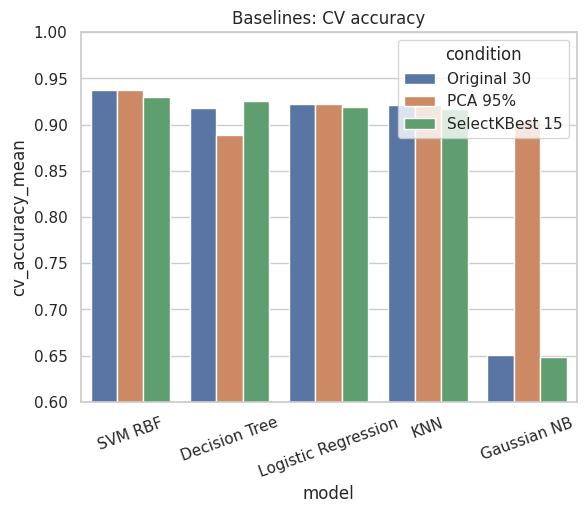

In [2]:
sns.barplot(data=b, x='model', y='cv_accuracy_mean', hue='condition'); plt.ylim(0.6,1); plt.xticks(rotation=20); plt.title('Baselines: CV accuracy'); plt.show()

**Observation:** SVM (RBF) is the strongest baseline (~93.7%). Gaussian NB collapses to ~65% on raw/selected features (it labels almost everything phishing: recall 1.0) because its independence assumption is violated by correlated features.